In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [ ]:
# 1) Generate artificial data from a second-order polynomial equation with added Gaussian noise.
X=np.linspace(-3,3,200)
y=X**2-X+3+np.random.normal(0,1,200)

In [ ]:
# 2) Segregate the data into training and test datasets.
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

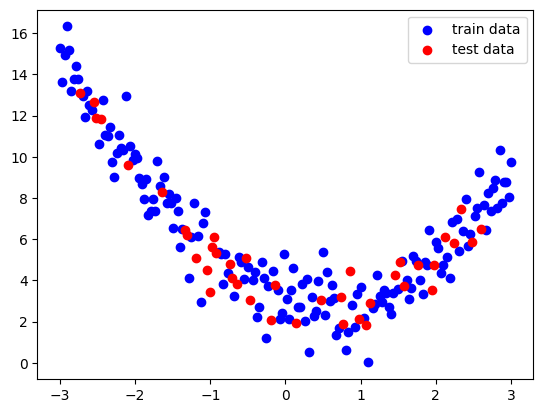

In [ ]:
plt.scatter(X_train,y_train,color='blue',label='train data')
plt.scatter(X_test,y_test,color='red',label='test data')
plt.legend()
plt.show()

In [ ]:
# 3) Model the data using a tenth-order polynomial with Linear Regression (basis functions approach).
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [175]:
poly=PolynomialFeatures(degree=10)
X_train_trans=poly.fit_transform(X_train.reshape(-1,1))
X_test_trans=poly.transform(X_test.reshape(-1,1))

In [176]:
lr=LinearRegression()
lr.fit(X_train_trans,y_train)

LinearRegression()

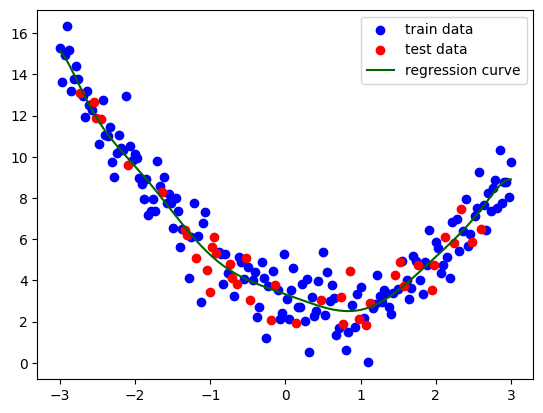

In [177]:
X_trans=poly.fit_transform(X.reshape(-1,1))
y_pred=lr.predict(X_trans)
plt.figure()
plt.scatter(X_train,y_train,color='blue',label='train data')
plt.scatter(X_test,y_test,color='red',label='test data')
plt.plot(X,y_pred,color='darkgreen',label='regression curve')
plt.legend()
plt.show()

In [178]:
# 4) Compute the root mean squared error (RMSE) on the test dataset.
from sklearn.metrics import mean_squared_error
y_pred=lr.predict(X_test_trans)
RMSE=np.sqrt(mean_squared_error(y_test,y_pred))
print(RMSE)

0.8252744232147157


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.218e+01, tolerance: 2.052e-01
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.217e+01, tolerance: 2.052e-01
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.217e+01, tolerance: 2.052e

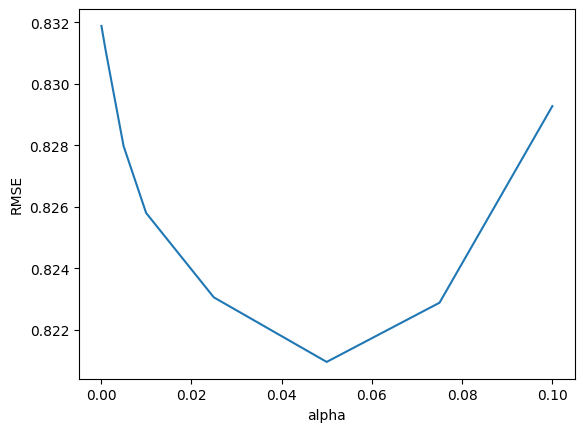

In [179]:
# 5) Now perform regularization using the LASSO model. Vary the regularization coefficient (alpha)
# and plot the variation of RMSE on the test dataset versus alpha. Take alpha to be positive.

from sklearn.linear_model import Lasso
alphas=[0.0001,0.0005,0.001,0.005,0.01,0.025,0.05,0.075,0.1]
RMSE=[]
for alpha in alphas:
  L=Lasso(alpha=alpha)
  L.fit(X_train_trans,y_train)
  y_pred=L.predict(X_test_trans)
  RMSE.append(np.sqrt(mean_squared_error(y_test,y_pred)))
plt.plot(alphas,RMSE)
plt.xlabel('alpha')
plt.ylabel('RMSE')
plt.show()